# Crypto Market Analysis · Part 1: Ethereum Market States
**ETH/USDT · 4H · Market regimes / Глобальні ринкові стани**

Explore five states — **UpTrend, DownTrend, UpSlide, DownSlide, Flat** — in any chosen date range.  

**Data granularity :** one CSV row represents an entire market segment, **not** a 4H candle. The price chart shows *segment-average close* unless optional 4H OHLC data are supplied or downloaded. No candle prices are reconstructed from summary statistics.

In [1]:
from pathlib import Path
import pandas as pd

files = list(
    Path("/kaggle/input").rglob(
        "ethusdt_4h_global_states_enriched_atr_adx7.csv"
    )
)

if not files:
    raise FileNotFoundError(
        "Dataset not found. Add it via Kaggle → Add Input."
    )

df = pd.read_csv(files[0])

print(f"Loaded: {files[0]}")
print(f"Shape: {df.shape}")

display(df.head())

Loaded: /kaggle/input/datasets/kupershtein/ethereum-4h-market-states-with-atr-and-adx/ethusdt_4h_global_states_enriched_atr_adx7.csv
Shape: (82, 49)


,segment_id,start_utc,end_utc,sub_state,amplitude,state,direction,type,name,length_bars,...,adx_mean,adx_min,adx_max,adx_std,count_bullish,count_bearish,bullish_pct,bearish_pct,canonical_name,label_consistent
0,1,2018-01-10T00:00:00Z,2018-01-16T04:00:00Z,7,20.0,3,Flat,Flat,Flat,38,...,28.1,17.8,38.5,5.7,17,21,44.7,55.3,Flat,1
1,2,2018-01-16T08:00:00Z,2018-01-17T12:00:00Z,2,10.0,2,Down,Trend,DownTrend,8,...,51.4,30.8,67.2,12.9,0,8,0.0,100.0,DownTrend,1
2,3,2018-01-17T16:00:00Z,2018-02-01T12:00:00Z,5,42.0,3,Up,Slide,UpSlide,90,...,35.2,16.7,70.5,11.8,41,49,45.6,54.4,UpSlide,1
3,4,2018-02-01T16:00:00Z,2018-02-06T04:00:00Z,2,30.0,2,Down,Trend,DownTrend,28,...,50.5,27.9,66.6,11.2,0,28,0.0,100.0,DownTrend,1
4,5,2018-02-06T08:00:00Z,2018-02-22T16:00:00Z,5,49.0,3,Up,Slide,UpSlide,92,...,29.2,10.5,68.3,13.0,43,49,46.7,53.3,UpSlide,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   segment_id          82 non-null     int64  
 1   start_utc           82 non-null     object 
 2   end_utc             82 non-null     object 
 3   sub_state           82 non-null     int64  
 4   amplitude           82 non-null     float64
 5   state               82 non-null     int64  
 6   direction           82 non-null     object 
 7   type                82 non-null     object 
 8   name                82 non-null     object 
 9   length_bars         82 non-null     int64  
 10  size_pct            82 non-null     float64
 11  speed_pct           82 non-null     float64
 12  speed_abs           82 non-null     float64
 13  prev_sub_state_1    82 non-null     int64  
 14  prev_amplitude_1    82 non-null     float64
 15  prev_state_1        82 non-null     int64  
 16  prev_direc

## 1. Settings
Change only `START_DATE` and `END_DATE` for a different period. All timestamps are UTC.  

In [3]:
# Date range 
START_DATE = "2018-01-01"
END_DATE = "2022-08-01"

SYMBOL = "ETHUSDT"
INTERVAL = "4h"
DATASET_FILENAME = "ethusdt_4h_global_states_enriched_atr_adx7.csv"

# Optional: true 4H closing prices
# Keep False to run completely offline with only this Kaggle dataset.
DOWNLOAD_BINANCE_OHLC = True   # Set True when Kaggle Internet is enabled
LOCAL_OHLC_CSV = None         # Optional local CSV: open_time/datetime + close


## 2. Load data 

Attach the Kaggle dataset **Ethereum 4H Market States with ATR & ADX** under **Add Input**.  
The CSV is found automatically in Kaggle's `/kaggle/input/` or beside this notebook.

In [4]:
from pathlib import Path
import json
from urllib.parse import urlencode
from urllib.request import urlopen, Request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from IPython.display import display

STATE_ORDER = ["UpTrend", "DownTrend", "UpSlide", "DownSlide", "Flat"]
STATE_COLORS = {
    "UpTrend": "#159957",
    "DownTrend": "#d64545",
    "UpSlide": "#79c99e",
    "DownSlide": "#ec9b45",
    "Flat": "#88929e",
}

# Kaggle / local /mnt/data
candidates = list(Path('/kaggle/input').rglob(DATASET_FILENAME)) if Path('/kaggle/input').exists() else []
candidates += [Path(DATASET_FILENAME), Path('/mnt/data') / DATASET_FILENAME,
               Path('/mnt/data/ETHUSDT_Kaggle_Single_Dataset_v3') / DATASET_FILENAME]
paths = [p for p in candidates if p.is_file()]
if not paths:
    raise FileNotFoundError(f"Attach the Kaggle dataset or put {DATASET_FILENAME} next to the notebook.")
DATASET_PATH = paths[0]

states = pd.read_csv(DATASET_PATH, parse_dates=['start_utc', 'end_utc'])
for col in ['start_utc', 'end_utc']:
    states[col] = pd.to_datetime(states[col], utc=True)
states = states.sort_values(['start_utc','segment_id']).reset_index(drop=True)

required = {'segment_id','start_utc','end_utc','name','sub_state','close_mean',
            'atr_pct_mean','adx_mean','length_bars'}
assert required.issubset(states.columns), f"Missing columns: {required - set(states.columns)}"
print(f"Loaded: {DATASET_PATH.name} | {len(states)} segments | {states.start_utc.min():%Y-%m-%d} – {states.end_utc.max():%Y-%m-%d}")


Loaded: ethusdt_4h_global_states_enriched_atr_adx7.csv | 82 segments | 2018-01-10 – 2022-08-14


## 3. Filter the time range
A state is included if its interval **overlaps** the chosen period. State boundaries are clipped to the plot window.  

In [5]:
start = pd.Timestamp(START_DATE, tz='UTC')
end_exclusive = pd.Timestamp(END_DATE, tz='UTC') + pd.Timedelta(days=1)
if start >= end_exclusive:
    raise ValueError("START_DATE must be on or before END_DATE")

selected = states.loc[
    (states['start_utc'] < end_exclusive) &
    ((states['end_utc'] + pd.Timedelta(hours=4)) > start)
].copy()
if selected.empty:
    raise ValueError("No market states overlap the selected date range.")

# start/end in the dataset are 4H candle *opening* timestamps (inclusive).
selected['plot_start'] = selected['start_utc'].clip(lower=start)
selected['plot_end'] = (selected['end_utc'] + pd.Timedelta(hours=4)).clip(upper=end_exclusive)
selected['hours_in_range'] = (
    selected['plot_end'] - selected['plot_start']
).dt.total_seconds() / 3600
selected = selected[selected['hours_in_range'] > 0].copy()

print(f"UTC interval: {START_DATE} to {END_DATE} (inclusive)")
print(f"Overlapping segments: {len(selected)}")
display(selected[['segment_id','plot_start','plot_end','name','close_mean']].head(8))


UTC interval: 2018-01-01 to 2022-08-01 (inclusive)
Overlapping segments: 82


,segment_id,plot_start,plot_end,name,close_mean
0,1,2018-01-10 00:00:00+00:00,2018-01-16 08:00:00+00:00,Flat,1281.0
1,2,2018-01-16 08:00:00+00:00,2018-01-17 16:00:00+00:00,DownTrend,1023.5
2,3,2018-01-17 16:00:00+00:00,2018-02-01 16:00:00+00:00,UpSlide,1071.7
3,4,2018-02-01 16:00:00+00:00,2018-02-06 08:00:00+00:00,DownTrend,885.9
4,5,2018-02-06 08:00:00+00:00,2018-02-22 20:00:00+00:00,UpSlide,871.9
5,6,2018-02-22 20:00:00+00:00,2018-03-30 16:00:00+00:00,DownSlide,677.9
6,7,2018-03-30 16:00:00+00:00,2018-04-09 12:00:00+00:00,Flat,388.0
7,8,2018-04-09 12:00:00+00:00,2018-05-06 04:00:00+00:00,UpTrend,598.4


## 4. Real 4H prices

To plot actual 4H closing prices, set `DOWNLOAD_BINANCE_OHLC = True` (requires Kaggle Internet), or supply a local candle CSV via `LOCAL_OHLC_CSV`.

The Binance public klines endpoint does not require an API key. If access is unavailable, the notebook keeps working with dataset summaries.

In [6]:
# Source - https://stackoverflow.com/a/74628882
# Posted by KuLeMi, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-14, License - CC BY-SA 4.0

import requests
import datetime
import pandas as pd
import numpy as np

def get_binance_data_by_requests(ticker='ETHUSDT', interval='4h', start=start, end=end_exclusive):
  """
  interval: str tick interval - 4h/1h/1d ...
  """
  columns = ['open_time','open', 'high', 'low', 'close', 'volume','close_time', 'qav','num_trades','taker_base_vol','taker_quote_vol', 'ignore']
  usecols=['open', 'high', 'low', 'close', 'volume', 'qav','num_trades','taker_base_vol','taker_quote_vol']
  start = int(datetime.datetime.timestamp(pd.to_datetime(start))*1000)
  end_u = int(datetime.datetime.timestamp(pd.to_datetime(end))*1000)
  df = pd.DataFrame()
  print(f'Downloading {interval} {ticker} ohlc-data ...', end=' ')
  while True:
    url = f'https://www.binance.com/api/v3/klines?symbol={ticker}&interval={interval}&limit=1000&startTime={start}#&endTime={end_u}'
    data = pd.DataFrame(requests.get(url, headers={'Cache-Control': 'no-cache', "Pragma": "no-cache"}).json(), columns=columns, dtype=np.float64)    
    start = int(data.open_time.tolist()[-1])+1
    data.index = [pd.to_datetime(x, unit='ms').strftime('%Y-%m-%d %H:%M:%S') for x in data.open_time]
    data = data[usecols]
    df = pd.concat([df, data], axis=0)
    if end in data.index.tolist():
      break
  print('Done.')
  df.index = pd.to_datetime(df.index)
  df = df.loc[:end]
  df = df.reset_index().rename(columns={'index':'datetime'})
  df['datetime'] = pd.to_datetime(df['datetime'], unit='ms', utc=True)  
  return df[['datetime', 'open', 'high', 'low', 'close']]

prices = get_binance_data_by_requests(ticker='ETHUSDT', interval='4h', start='2018-01-01 00:00:00', end='2022-08-01 00:00:00')
prices


,datetime,open,high,low,close
0,2018-01-01 00:00:00+00:00,733.01,737.99,716.80,734.50
1,2018-01-01 04:00:00+00:00,734.99,763.55,730.01,751.99
2,2018-01-01 08:00:00+00:00,751.77,759.00,730.58,741.01
3,2018-01-01 12:00:00+00:00,741.01,752.27,724.15,748.80
4,2018-01-01 16:00:00+00:00,748.27,749.98,733.00,746.23
...,...,...,...,...,...
10018,2022-07-31 08:00:00+00:00,1697.93,1724.19,1686.06,1718.57
10019,2022-07-31 12:00:00+00:00,1718.56,1722.32,1692.42,1712.04
10020,2022-07-31 16:00:00+00:00,1712.05,1754.69,1687.01,1717.37
10021,2022-07-31 20:00:00+00:00,1717.37,1724.93,1666.00,1678.12


In [7]:
# def download_binance_closes(symbol, interval, start_ts, end_ts):
#     """Public Binance spot 4H kline API; one request per <=1000 candles."""
#     start_ms = int(start_ts.timestamp() * 1000)
#     end_ms = int(end_ts.timestamp() * 1000)
#     all_rows = []
#     while start_ms < end_ms:
#         params = urlencode({'symbol': symbol, 'interval': interval,
#                             'startTime': start_ms, 'endTime': end_ms-1, 'limit':1000})
#         req = Request('https://api.binance.com/api/v3/klines?' + params,
#                       headers={'User-Agent':'Mozilla/5.0'})
#         with urlopen(req, timeout=12) as response:
#             batch = json.load(response)
#         if not isinstance(batch,list) or not batch:
#             break
#         all_rows.extend(batch)
#         next_start = int(batch[-1][0]) + 1
#         if next_start <= start_ms:
#             break
#         start_ms = next_start
#         if len(batch) < 1000:
#             break
#     if not all_rows:
#         return None
#     result = pd.DataFrame(all_rows)
    
#     result = result.rename(columns={0:'datetime', 1:'open', 2:'high', 3:'low', 4:'close'})[['datetime','open', 'high', 'low', 'close']]
#     result['datetime'] = pd.to_datetime(result['datetime'], unit='ms', utc=True)
#     cols = ['open', 'high', 'low', 'close']
#     result[cols] = result[cols].apply(pd.to_numeric, errors='coerce')
    
#     return result.dropna().drop_duplicates('datetime').sort_values('datetime')

# prices = None
# if LOCAL_OHLC_CSV:
#     try:
#         raw = pd.read_csv(LOCAL_OHLC_CSV)
#         ts_col = next((x for x in ['datetime','open_time','timestamp','date','time'] if x in raw.columns), None)
#         if ts_col is None or 'close' not in raw.columns:
#             raise ValueError('Expected a date/time column and close column')
#         ts = raw[ts_col]
#         if pd.api.types.is_numeric_dtype(ts):
#             unit = 'ms' if ts.dropna().median() > 1e11 else 's'
#             times = pd.to_datetime(ts, unit=unit, utc=True)
#         else:
#             times = pd.to_datetime(ts, utc=True)
#         prices = pd.DataFrame({'datetime':times, 'close':pd.to_numeric(raw['close'],errors='coerce')})
#         prices = prices.dropna().query('datetime >= @start and datetime < @end_exclusive')
#     except Exception as exc:
#         print('Local OHLC unavailable:',exc)
# elif DOWNLOAD_BINANCE_OHLC:
#     try:
#         prices = download_binance_closes(SYMBOL, INTERVAL, start, end_exclusive)
#     except Exception as exc:
#         print('Binance OHLC unavailable; using segment averages instead:', type(exc).__name__,str(exc)[:160])

# if prices is not None and prices.empty:
#     prices = None
# print('Price series:', f'{len(prices)} actual 4H candles' if prices is not None else 'segment-level mean prices (offline mode)')


In [8]:
prices.head()

,datetime,open,high,low,close
0,2018-01-01 00:00:00+00:00,733.01,737.99,716.80,734.50
1,2018-01-01 04:00:00+00:00,734.99,763.55,730.01,751.99
2,2018-01-01 08:00:00+00:00,751.77,759.00,730.58,741.01
3,2018-01-01 12:00:00+00:00,741.01,752.27,724.15,748.80
4,2018-01-01 16:00:00+00:00,748.27,749.98,733.00,746.23


## 5. Market states on the price chart 
The colored bands represent the state assigned to each time segment. A separate strip makes regime boundaries easy to see.  

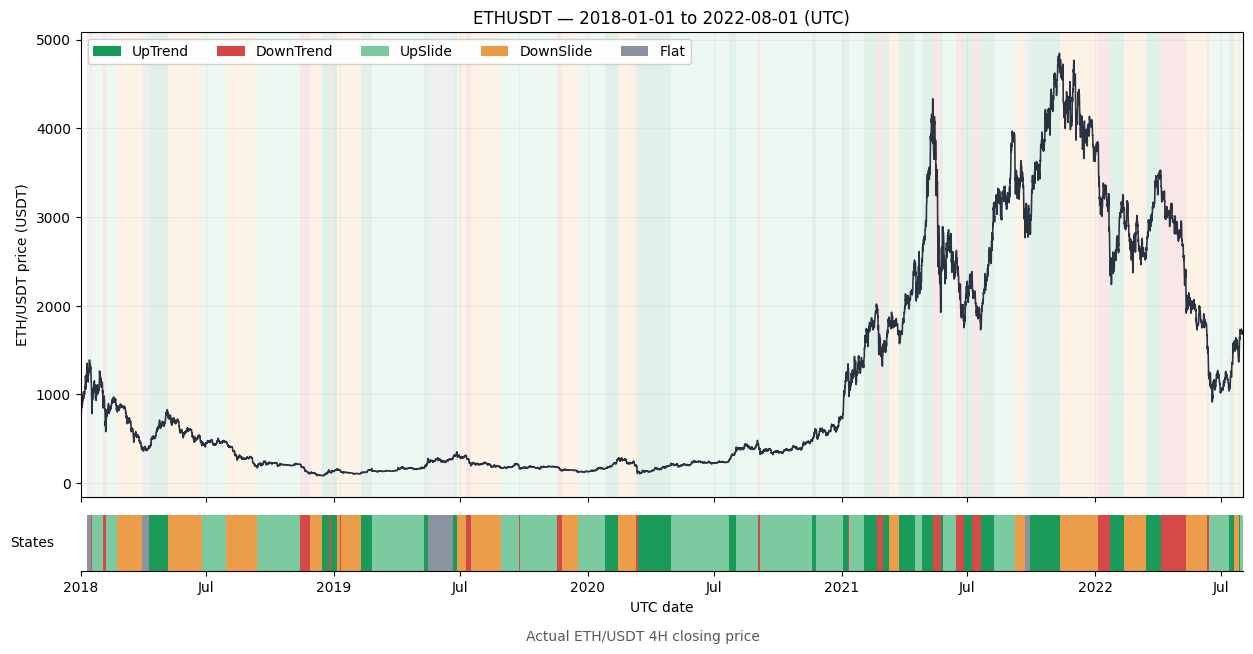

In [9]:
fig, (ax, ax_states) = plt.subplots(
    2, 1, figsize=(15, 7), sharex=True,
    gridspec_kw={'height_ratios':[5,0.6], 'hspace':0.07}
)

# Light state shading on price chart + bold regime timeline below.
for row in selected.itertuples(index=False):
    color = STATE_COLORS.get(row.name, '#aeb8c2')
    s = row.plot_start.to_pydatetime()
    e = row.plot_end.to_pydatetime()
    ax.axvspan(s, e, color=color, alpha=0.13, lw=0)
    ax_states.axvspan(s, e, color=color, alpha=0.98, lw=0)

if prices is not None:
    ax.plot(prices['datetime'], prices['close'], color='#293241', lw=1.15, label='Actual 4H close')
    price_label = 'Actual ETH/USDT 4H closing price'
else:
    for row in selected.itertuples(index=False):
        s = row.plot_start.to_pydatetime()
        e = row.plot_end.to_pydatetime()
        color = STATE_COLORS.get(row.name, '#aeb8c2')
        ax.hlines(row.close_mean, s, e, color=color, lw=2.6)
        ax.plot(s, row.close_mean, marker='o', ms=3, color=color)
    price_label = 'Mean close per full segment (not 4H candle prices)'

legend_items = [Patch(facecolor=STATE_COLORS[x], label=x) for x in STATE_ORDER if x in selected.name.unique()]
ax.legend(handles=legend_items, loc='upper left', ncol=min(5,len(legend_items)),framealpha=.92)
ax.set(title=f'{SYMBOL} — {START_DATE} to {END_DATE} (UTC)', ylabel='ETH/USDT price (USDT)')
ax.grid(alpha=.18)
ax.set_xlim(start.to_pydatetime(),end_exclusive.to_pydatetime())
ax_states.set_yticks([])
ax_states.set_ylabel('States',rotation=0,labelpad=35,va='center')
ax_states.set_ylim(0,1)
ax_states.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=11))
ax_states.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax_states.xaxis.get_major_locator()))
ax_states.set_xlabel('UTC date')
for spine in ['top','right','left']:
    ax_states.spines[spine].set_visible(False)
fig.text(.5,.01,price_label,ha='center',fontsize=10,color='#515964')
plt.show()


## 6. Market states on the interactive OHLC chart

In [10]:
# import plotly.io as pio
# pio.renderers.default = "plotly_mimetype+png"

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ============================================================
# 1. SETTINGS
# ============================================================

START_DATE = "2021-01-01"
END_DATE = "2021-06-30"

STATE_COLORS = {
    "UpTrend": "#2ca02c",    # Green
    "DownTrend": "#d62728",  # Red
    "UpSlide": "#e3a124",    # Orange
    "DownSlide": "#1f77b4",  # Blue
    "Flat": "#8c8c8c"        # Gray
}

# ============================================================
# 2. PREPARE DATA
# ============================================================

start = pd.Timestamp(START_DATE, tz="UTC")
end = pd.Timestamp(END_DATE, tz="UTC") + pd.Timedelta(days=1)

# OHLC prices
candles = prices.copy()

candles["datetime"] = pd.to_datetime(
    candles["datetime"], utc=True
)

candles = candles[
    (candles["datetime"] >= start) &
    (candles["datetime"] < end)
].sort_values("datetime")

# Global market states
states = df.copy()

states["start_utc"] = pd.to_datetime(
    states["start_utc"], utc=True
)

states["end_utc"] = pd.to_datetime(
    states["end_utc"], utc=True
)

# end_utc is the opening timestamp of the last 4H candle
states["finish"] = states["end_utc"] + pd.Timedelta(hours=4)

states = states[
    (states["start_utc"] < end) &
    (states["finish"] > start)
].sort_values("start_utc").copy()

states["plot_start"] = states["start_utc"].clip(lower=start)
states["plot_end"] = states["finish"].clip(upper=end)

states["duration_days"] = (
    states["plot_end"] - states["plot_start"]
).dt.total_seconds() / 86400

if candles.empty:
    raise ValueError("No OHLC candles in the selected date range")

if states.empty:
    raise ValueError("No market states in the selected date range")

# ============================================================
# 3. CREATE PLOTLY FIGURE
# ============================================================

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    row_heights=[0.88, 0.12],
    vertical_spacing=0.025
)

# ------------------------------------------------------------
# Candlestick chart
# ------------------------------------------------------------

fig.add_trace(
    go.Candlestick(
        x=candles["datetime"],
        open=candles["open"],
        high=candles["high"],
        low=candles["low"],
        close=candles["close"],

        increasing_line_color="#16a34a",
        decreasing_line_color="#dc2626",

        name="ETH/USDT",
        showlegend=False
    ),
    row=1,
    col=1
)

# ------------------------------------------------------------
# Market state backgrounds and timeline bars
# ------------------------------------------------------------

shown_states = set()

for state in states.itertuples(index=False):

    name = state.name
    color = STATE_COLORS.get(name, "#808080")

    # Background color on candlestick chart
    fig.add_vrect(
        x0=state.plot_start,
        x1=state.plot_end,
        fillcolor=color,
        opacity=0.13,
        line_width=0,
        layer="below",
        row=1,
        col=1
    )

    # Hover information
    hover_text = (
        f"<b>{name}</b><br>"
        f"Start: {state.plot_start:%Y-%m-%d %H:%M}<br>"
        f"End: {state.plot_end:%Y-%m-%d %H:%M}<br>"
        f"Duration: {state.duration_days:.1f} days<br>"
        f"ATR: {state.atr_pct_mean:.2f}%<br>"
        f"ADX: {state.adx_mean:.2f}"
    )

    # State timeline below candlesticks
    fig.add_trace(
        go.Scatter(
            x=[state.plot_start, state.plot_end],
            y=[0.5, 0.5],

            mode="lines",

            line=dict(
                color=color,
                width=20
            ),

            name=name,
            legendgroup=name,
            showlegend=name not in shown_states,

            hovertemplate=hover_text + "<extra></extra>"
        ),
        row=2,
        col=1
    )

    shown_states.add(name)

# ============================================================
# 4. CHART STYLE
# ============================================================

fig.update_layout(
    title=dict(
        text=(
            "ETH/USDT 4H — Global Market States"
            f"<br><sup>{START_DATE} — {END_DATE}</sup>"
        ),
        x=0.02,
        y=0.98,
        xanchor="left",
        yanchor="top",
        font=dict(size=20)
    ),

    template="plotly_white",
    height=750,

    hovermode="closest",

    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.15,
        yanchor="top",
        font=dict(size=12),
        bgcolor="rgba(255,255,255,0.8)"
    ),

    margin=dict(
        l=60,
        r=30,
        t=110,
        b=110
    )
)

fig.update_yaxes(
    title_text="Price (USDT)",
    row=1,
    col=1
)

fig.update_yaxes(
    visible=False,
    range=[0, 1],
    fixedrange=True,
    row=2,
    col=1
)

fig.update_xaxes(
    range=[start, end],
    rangeslider_visible=False,
    row=1,
    col=1
)

fig.update_xaxes(
    range=[start, end],
    rangeslider_visible=False,
    title_text="Date (UTC)",
    row=2,
    col=1
)

# fig.show(
#     config={
#         "scrollZoom": True,
#         "displaylogo": False,
#         "responsive": True
#     }
# )

fig.show()
# fig.show(renderer="png", width=1100, height=650)
fig.write_html(
    "eth_market_states.html",
    include_plotlyjs=True
)

## 7. Market States Analytics

### Counts and duration shares refer **only to the selected window**. ATR% and ADX averages are from the **complete original segments**, not recalculated inside the filtered interval.

Segments: 82 | Labeled time: 1665.0 days


,Segments,Days in window,Time share (%),Mean ATR (%),Mean ADX
name,,,,,
UpTrend,23,349.2,21.0,3.5,40.8
DownTrend,19,151.3,9.1,5.0,47.7
UpSlide,20,663.2,39.8,3.1,35.3
DownSlide,16,441.3,26.5,3.0,35.2
Flat,4,60.0,3.6,4.4,32.9


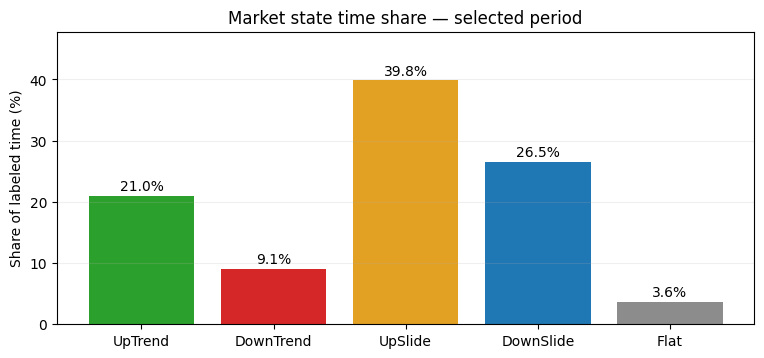

In [11]:
summary = (selected.groupby('name',observed=True)
    .agg(segments=('segment_id','count'),
         coverage_days=('hours_in_range',lambda x: x.sum()/24),
         mean_atr_pct=('atr_pct_mean','mean'),
         mean_adx=('adx_mean','mean'))
    .reindex([x for x in STATE_ORDER if x in selected.name.unique()]))
summary['time_share_pct'] = 100 * summary['coverage_days'] / summary['coverage_days'].sum()
summary = summary[['segments','coverage_days','time_share_pct','mean_atr_pct','mean_adx']]
summary.columns = ['Segments','Days in window','Time share (%)','Mean ATR (%)','Mean ADX']
print(f"Segments: {len(selected)} | Labeled time: {summary['Days in window'].sum():.1f} days")
display(summary.round(1))

fig, ax = plt.subplots(figsize=(9,3.8))
labels = summary.index.tolist()
ax.bar(labels, summary['Time share (%)'], color=[STATE_COLORS[x] for x in labels])
ax.set(ylabel='Share of labeled time (%)', title='Market state time share — selected period')
ax.grid(axis='y',alpha=.2)
for i,value in enumerate(summary['Time share (%)']):
    ax.text(i,value+0.4,f'{value:.1f}%',ha='center',va='bottom',fontsize=10)
ax.set_ylim(0,max(summary['Time share (%)'])*1.2)
plt.show()


### Duration of each complete market segment in days

In [12]:

states_analysis = states.copy()

states_analysis["duration_days"] = (
    states_analysis["finish"] - states_analysis["start_utc"]
).dt.total_seconds() / 86400

duration_stats = (
    states_analysis.groupby("name")
    .agg(
        segments=("name", "size"),
        median_days=("duration_days", "median"),
        mean_days=("duration_days", "mean"),
        max_days=("duration_days", "max")
    )
    .round(2)
)

display(duration_stats)

,segments,median_days,mean_days,max_days
name,,,,
DownSlide,1,15.00,15.00,15.00
DownTrend,4,9.92,8.25,11.83
UpSlide,4,20.50,22.29,38.50
UpTrend,7,11.33,12.55,22.33


### Vloatility and ternd stregth

In [13]:
indicator_stats = (
    states.groupby("name")
    .agg(
        segments=("name", "size"),
        mean_atr_pct=("atr_pct_mean", "mean"),
        median_atr_pct=("atr_pct_mean", "median"),
        mean_adx=("adx_mean", "mean"),
        median_adx=("adx_mean", "median")
    )
    .round(2)
)

display(indicator_stats)

,segments,mean_atr_pct,median_atr_pct,mean_adx,median_adx
name,,,,,
DownSlide,1,2.60,2.6,31.50,31.50
DownTrend,4,6.08,6.2,43.05,46.20
UpSlide,4,4.38,4.6,32.52,32.75
UpTrend,7,4.34,3.5,37.11,36.80


### Market State Transition Matrix

In [14]:
import plotly.express as px

# Use the full dataset to preserve consecutive transitions
state_sequence = df.sort_values("start_utc").copy()

state_sequence["next_state"] = state_sequence["name"].shift(-1)

transitions = pd.crosstab(
    state_sequence["name"],
    state_sequence["next_state"],
    normalize="index"
) * 100

fig_transitions = px.imshow(
    transitions,
    text_auto=".1f",
    color_continuous_scale="Blues",
    labels={
        "x": "Next State",
        "y": "Current State",
        "color": "Probability (%)"
    },
    title="ETH/USDT — Market State Transitions"
)

fig_transitions.update_layout(
    height=500,
    template="plotly_white"
)

fig_transitions.show()
# fig_transitions.show(renderer="png", width=1100, height=650)
fig_transitions.write_html(
    "eth_market_states_transitions.html",
    include_plotlyjs=True
)

### Bullish vs Bearish Dominance

In [15]:
import pandas as pd
import plotly.graph_objects as go

# Use the complete dataset
state_stats = (
    df.groupby("name", as_index=False)
    .agg(
        bullish=("count_bullish", "sum"),
        bearish=("count_bearish", "sum"),
        segments=("name", "size")
    )
)

# Calculate percentages weighted by number of 4H bars
state_stats["total"] = (
    state_stats["bullish"] + state_stats["bearish"]
)

state_stats["bullish_pct"] = (
    state_stats["bullish"] / state_stats["total"] * 100
)

state_stats["bearish_pct"] = (
    state_stats["bearish"] / state_stats["total"] * 100
)

state_order = [
    "UpTrend", "DownTrend",
    "UpSlide", "DownSlide", "Flat"
]

state_stats["name"] = pd.Categorical(
    state_stats["name"],
    categories=state_order,
    ordered=True
)

state_stats = state_stats.sort_values("name")

fig = go.Figure()

fig.add_trace(
    go.Bar(
        y=state_stats["name"],
        x=state_stats["bullish_pct"],
        name="Bullish (+DI > -DI)",
        orientation="h",
        marker_color="#16a34a",
        text=state_stats["bullish_pct"].round(1),
        texttemplate="%{text}%",
        textposition="inside"
    )
)

fig.add_trace(
    go.Bar(
        y=state_stats["name"],
        x=state_stats["bearish_pct"],
        name="Bearish (+DI ≤ -DI)",
        orientation="h",
        marker_color="#dc2626",
        text=state_stats["bearish_pct"].round(1),
        texttemplate="%{text}%",
        textposition="inside"
    )
)

fig.update_layout(
    title="ETH/USDT — Bullish vs Bearish DI Dominance",
    barmode="stack",
    template="plotly_white",
    height=420,
    xaxis_title="Share of 4H Bars (%)",
    yaxis_title="Market State",
    xaxis=dict(range=[0, 100]),
    legend=dict(
        orientation="h",
        y=-0.25,
        x=0.5,
        xanchor="center"
    ),
    margin=dict(t=70, b=100)
)

fig.show()
# fig.show(renderer="png", width=1100, height=650)
fig_transitions.write_html(
    "eth_market_states_Dominance.html",
    include_plotlyjs=True)

**Key Insight:** Bullish and bearish directional dominance varies across market states. UpTrend segments exhibit strong bullish dominance, while DownTrend segments show predominantly bearish conditions. Slide states demonstrate a more balanced distribution, suggesting weaker directional consistency than established trends.

## Conclusions & Key Takeaways

In this notebook, the Ethereum (ETH/USDT) market behavior was explored using historical 4-hour data and five predefined global market states: UpTrend, DownTrend, UpSlide, DownSlide, and Flat.

### Analysis highlights several key observations:

**Market State Distribution:** Market conditions vary significantly in frequency and duration. Corrective (Slide) states occupy a substantial portion of the analyzed historical period.

**State Persistence:** Different market states exhibit different durations, suggesting that some conditions are more persistent than others.

**Volatility & Trend Strength:** ATR and ADX provide additional insights into how volatility and directional strength differ across market states.

**Directional Dominance:** UpTrend and DownTrend states exhibit stronger directional consistency based on +DI and −DI, while Slide states tend to show more balanced directional behavior.

**State Transitions:** The transition matrix reveals historical patterns in how market states evolve, providing a foundation for further research into market dynamics.

### Final Thoughts

The results demonstrate that cryptocurrency market behavior can be studied through distinct market states, each characterized by different directional, volatility, and persistence patterns.

Understanding these differences may provide useful insights for technical analysis, trading strategy research, and future machine learning applications.

However, these findings are descriptive and based on historical, completed market segments. They should not be interpreted as validated predictive signals.

### What's Next?

Future research may focus on market state prediction, transition probabilities, and machine learning approaches to identifying changes in market conditions.

### If you found this notebook useful, please consider giving it an upvote on [Kaggle!](https://www.kaggle.com/code/kupershtein/crypto-market-analysis-eth-market-states) Your support helps motivate future notebooks in the Crypto Market Analysis series.